<a href="https://colab.research.google.com/github/ShaileshM-ds/ML-lab/blob/main/Lab8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Algorithm        Silhouette    ARI vs True
------------------------------------------
K-Means               0.460          0.620
Spectral              0.463          0.645
Hierarchical          0.447          0.615


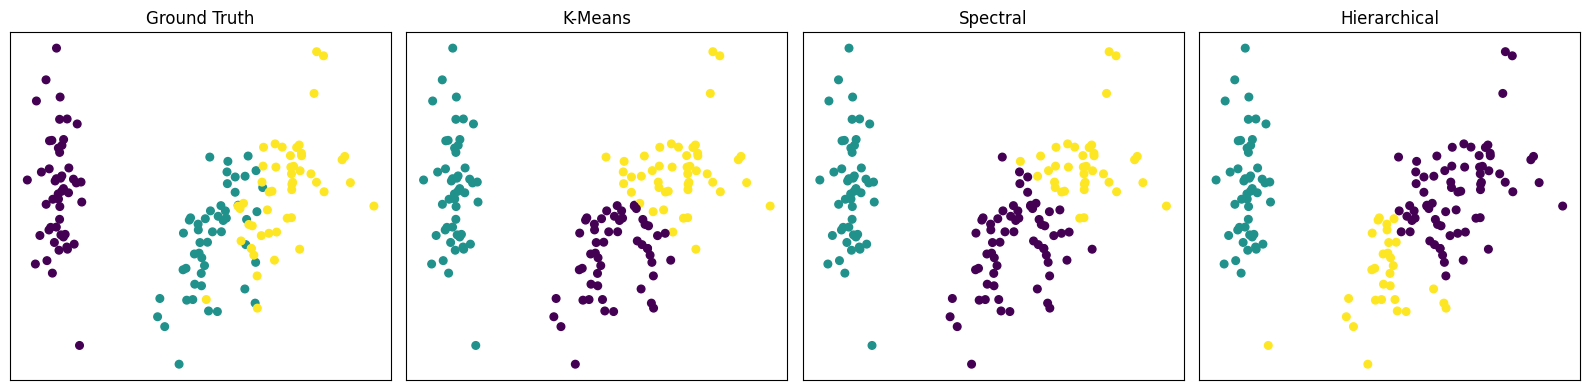

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, SpectralClustering, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

# ---------- 1. Load & prepare data ----------
X, y_true = load_iris(return_X_y=True)
X = StandardScaler().fit_transform(X)

# ---------- 2. Apply the 3 clustering algorithms ----------
k = 3  # Iris has 3 species

kmeans   = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
spectral = SpectralClustering(n_clusters=k, affinity='rbf',
                              gamma=1.0, random_state=42).fit(X)
hier     = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(X)

models = {
    'K-Means':      kmeans.labels_,
    'Spectral':     spectral.labels_,
    'Hierarchical': hier.labels_,
}

# ---------- 3. Compare results ----------
print(f"{'Algorithm':<15}{'Silhouette':>12}{'ARI vs True':>15}")
print("-" * 42)
for name, labels in models.items():
    sil = silhouette_score(X, labels)
    ari = adjusted_rand_score(y_true, labels)
    print(f"{name:<15}{sil:>12.3f}{ari:>15.3f}")

# ---------- 4. Visualize (project to 2D with PCA) ----------
X_2d = PCA(n_components=2, random_state=42).fit_transform(X)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
titles = ['Ground Truth'] + list(models.keys())
labels_all = [y_true] + list(models.values())

for ax, title, labels in zip(axes, titles, labels_all):
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='viridis', s=30)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()